# NYC Yellow Taxi — Zone-Level Demand Forecasting

## Phase 1: Zone-Hour Demand Panel

Objective:
Construct an hourly pickup-demand panel from the
2025 NYC Yellow Taxi pickup-valid trip records.

Pilot month: January 2025

Forecasting target:
Number of taxi pickups per zone per hour.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

# Locate repository root
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "cleaned_trips"

JAN_PATH = DATA_DIR / "cleaned_2025-01.parquet"

print("Project root:", PROJECT_ROOT)
print("January file exists:", JAN_PATH.exists())

Project root: /Users/wushixundelaopo/Desktop/Urban_Mobility_Mining
January file exists: True


In [2]:
# Load January pickup-valid data
df_jan = pd.read_parquet(JAN_PATH)

print("January records:", f"{len(df_jan):,}")

print("\nColumns:")
print(df_jan.columns.tolist())

print("\nData types:")
print(df_jan.dtypes)

display(df_jan.head())

January records: 3,475,204

Columns:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'PULocationID', 'DOLocationID', 'trip_distance', 'trip_duration_min', 'valid_dropoff_zone', 'valid_duration', 'valid_distance', 'zero_duration', 'negative_duration', 'valid_od']

Data types:
VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
PULocationID                      int32
DOLocationID                      int32
trip_distance                   float64
trip_duration_min               float64
valid_dropoff_zone                 bool
valid_duration                     bool
valid_distance                     bool
zero_duration                      bool
negative_duration                  bool
valid_od                           bool
dtype: object


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,trip_distance,trip_duration_min,valid_dropoff_zone,valid_duration,valid_distance,zero_duration,negative_duration,valid_od
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,229,237,1.60,8.350000,True,True,True,False,False,True
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,236,237,0.50,2.550000,True,True,True,False,False,True
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,141,141,0.60,1.950000,True,True,True,False,False,True
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,244,244,0.52,5.566667,True,True,True,False,False,True
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,244,116,0.66,3.533333,True,True,True,False,False,True


## January 2025 — Hourly Pickup Aggregation

Aggregate pickup-valid trip records into hourly demand
counts for each taxi zone.

Unit of analysis: (PULocationID, pickup_hour).

In [3]:
# Step B1.2: Aggregate pickups by taxi zone and hour

jan_trips = df_jan[
    ["tpep_pickup_datetime", "PULocationID"]
].copy()

jan_trips["pickup_hour"] = (
    pd.to_datetime(jan_trips["tpep_pickup_datetime"])
    .dt.floor("h")
)

jan_hourly = (
    jan_trips
    .groupby(["PULocationID", "pickup_hour"])
    .size()
    .reset_index(name="pickup_count")
    .rename(columns={"PULocationID": "zone_id"})
    .sort_values(["zone_id", "pickup_hour"])
    .reset_index(drop=True)
)

print("January trips:", f"{len(jan_trips):,}")
print("Observed zone-hour combinations:", f"{len(jan_hourly):,}")
print("Unique pickup zones:", jan_hourly["zone_id"].nunique())

display(jan_hourly.head(10))

January trips: 3,475,204
Observed zone-hour combinations: 97,014
Unique pickup zones: 261


,zone_id,pickup_hour,pickup_count
0,1,2025-01-01 06:00:00,1
1,1,2025-01-01 09:00:00,4
2,1,2025-01-01 12:00:00,2
3,1,2025-01-01 13:00:00,4
4,1,2025-01-01 14:00:00,2
5,1,2025-01-01 15:00:00,3
6,1,2025-01-01 16:00:00,2
7,1,2025-01-01 17:00:00,1
8,1,2025-01-01 18:00:00,1
9,1,2025-01-01 20:00:00,1


In [4]:
# Validate hourly aggregation

original_count = len(df_jan)
aggregated_count = jan_hourly["pickup_count"].sum()

assert aggregated_count == original_count, (
    f"Count mismatch: {aggregated_count:,} != {original_count:,}"
)

assert not jan_hourly.duplicated(
    ["zone_id", "pickup_hour"]
).any(), "Duplicate zone-hour combinations found."

assert (jan_hourly["pickup_count"] > 0).all(), (
    "Observed zone-hour counts must be positive."
)

assert jan_hourly["pickup_hour"].min() >= pd.Timestamp("2025-01-01")
assert jan_hourly["pickup_hour"].max() < pd.Timestamp("2025-02-01")

print("All January aggregation checks passed!")
print("Total pickups:", f"{aggregated_count:,}")

All January aggregation checks passed!
Total pickups: 3,475,204


In [5]:
# Step B1.3 — Inspect pickup zone coverage

zone_summary = (
    df_jan.groupby("PULocationID")
    .size()
    .reset_index(name="pickup_count")
    .rename(columns={"PULocationID": "zone_id"})
    .sort_values("pickup_count", ascending=False)
)

print("Unique pickup zones:", len(zone_summary))

print("\nTop 10 pickup zones:")
display(zone_summary.head(10))

print("\nBottom 10 pickup zones:")
display(zone_summary.tail(10))

print("\nSpecial-purpose zones:")
display(zone_summary[zone_summary["zone_id"].isin([264, 265])])

print("\nZone ID range:")
print(
    zone_summary["zone_id"].min(),
    zone_summary["zone_id"].max()
)

Unique pickup zones: 261

Top 10 pickup zones:


,zone_id,pickup_count
156,161,169977
232,237,163703
231,236,155647
127,132,146135
225,230,125829
181,186,119130
157,162,117930
137,142,110584
234,239,96614
158,163,95905



Bottom 10 pickup zones:


,zone_id,pickup_count
105,109,4
4,5,3
43,44,3
106,111,3
199,204,3
182,187,2
171,176,2
98,99,1
83,84,1
194,199,1



Special-purpose zones:


,zone_id,pickup_count
259,264,8141
260,265,1380



Zone ID range:
1 265


In [6]:
# Step B1.4 — Define the candidate forecasting zone set

LOOKUP_PATH = PROJECT_ROOT / "data" / "external" / "taxi_zone_lookup.csv"

zone_lookup = pd.read_csv(LOOKUP_PATH)

print("Lookup columns:", zone_lookup.columns.tolist())

# Exclude non-geographic special-purpose zones
forecast_zone_ids = sorted(
    set(zone_lookup["LocationID"].dropna().astype(int))
    - {264, 265}
)

jan_zone_counts = (
    df_jan["PULocationID"].value_counts()
)

excluded_counts = jan_zone_counts[
    ~jan_zone_counts.index.isin(forecast_zone_ids)
]

print("\nCandidate forecasting zones:", len(forecast_zone_ids))
print("Observed candidate zones:",
      jan_hourly["zone_id"].isin(forecast_zone_ids).groupby(
          jan_hourly["zone_id"]
      ).first().sum())

print("\nExcluded pickup records:")
print(excluded_counts.sort_index())

print("\nJanuary pickups in candidate zones:",
      jan_zone_counts[
          jan_zone_counts.index.isin(forecast_zone_ids)
      ].sum())

display(
    zone_lookup[
        zone_lookup["LocationID"].isin([1, 264, 265])
    ]
)

Lookup columns: ['LocationID', 'Borough', 'Zone', 'service_zone']

Candidate forecasting zones: 263
Observed candidate zones: 259

Excluded pickup records:
PULocationID
264    8141
265    1380
Name: count, dtype: int64

January pickups in candidate zones: 3465683


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
263,264,Unknown,NaN,NaN
264,265,NaN,Outside of NYC,NaN


In [7]:
# Step B1.5 — Complete January Zone-Hour Panel

jan_hours = pd.date_range(
    start="2025-01-01",
    end="2025-02-01",
    freq="h",
    inclusive="left"
)

full_index = pd.MultiIndex.from_product(
    [forecast_zone_ids, jan_hours],
    names=["zone_id", "pickup_hour"]
)

jan_hourly_valid = jan_hourly[
    jan_hourly["zone_id"].isin(forecast_zone_ids)
].copy()

jan_panel = (
    jan_hourly_valid
    .set_index(["zone_id", "pickup_hour"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

jan_panel["pickup_count"] = jan_panel["pickup_count"].astype("int32")

print("Zones:", jan_panel["zone_id"].nunique())
print("Hours:", jan_panel["pickup_hour"].nunique())
print("Panel rows:", f"{len(jan_panel):,}")
print("Total pickups:", f"{jan_panel['pickup_count'].sum():,}")

display(jan_panel.head())

Zones: 263
Hours: 744
Panel rows: 195,672
Total pickups: 3,465,683


,zone_id,pickup_hour,pickup_count
0,1,2025-01-01 00:00:00,0
1,1,2025-01-01 01:00:00,0
2,1,2025-01-01 02:00:00,0
3,1,2025-01-01 03:00:00,0
4,1,2025-01-01 04:00:00,0


In [8]:
assert len(jan_panel) == 263 * 744
assert jan_panel["pickup_count"].sum() == 3_465_683
assert not jan_panel.duplicated(["zone_id", "pickup_hour"]).any()
assert jan_panel["pickup_count"].ge(0).all()
assert jan_panel.groupby("zone_id").size().eq(744).all()

print("All January panel validation checks passed!")
print("Zero-demand zone-hours:", (jan_panel["pickup_count"] == 0).sum())
print(
    "Zones with no January pickups:",
    jan_panel.groupby("zone_id")["pickup_count"].sum().eq(0).sum()
)

All January panel validation checks passed!
Zero-demand zone-hours: 99918
Zones with no January pickups: 4


## Zone-Level Demand Sparsity Diagnostics

Examine the distribution of hourly pickup demand
and the proportion of zero-demand hours across taxi zones.

In [9]:
# Step B1.6 — Zone-level demand sparsity diagnostics

zone_diagnostics = (
    jan_panel.groupby("zone_id")
    .agg(
        total_pickups=("pickup_count", "sum"),
        mean_hourly_pickups=("pickup_count", "mean"),
        max_hourly_pickups=("pickup_count", "max"),
        zero_hours=("pickup_count", lambda x: (x == 0).sum()),
    )
    .reset_index()
)

zone_diagnostics["zero_hour_pct"] = (
    zone_diagnostics["zero_hours"] / len(jan_hours) * 100
)

print("Zone-level demand summary:")

display(
    zone_diagnostics[
        [
            "total_pickups",
            "mean_hourly_pickups",
            "zero_hour_pct",
        ]
    ].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

print("\nZones with highest zero-hour percentages:")
display(
    zone_diagnostics
    .sort_values("zero_hour_pct", ascending=False)
    .head(10)
)

print("\nZones with lowest zero-hour percentages:")
display(
    zone_diagnostics
    .sort_values("zero_hour_pct")
    .head(10)
)

Zone-level demand summary:


,total_pickups,mean_hourly_pickups,zero_hour_pct
count,263.000000,263.000000,263.000000
mean,13177.501901,17.711696,51.064026
std,31207.124127,41.945059,34.112316
min,0.000000,0.000000,0.000000
10%,15.200000,0.020430,1.612903
25%,203.000000,0.272849,17.405914
50%,588.000000,0.790323,57.258065
75%,2729.000000,3.668011,79.099462
90%,52513.200000,70.582258,97.983871
95%,89104.900000,119.764651,99.462366



Zones with highest zero-hour percentages:


,zone_id,total_pickups,mean_hourly_pickups,max_hourly_pickups,zero_hours,zero_hour_pct
104,105,0,0.000000,0,744,100.000000
102,103,0,0.000000,0,744,100.000000
109,110,0,0.000000,0,744,100.000000
103,104,0,0.000000,0,744,100.000000
98,99,1,0.001344,1,743,99.865591
198,199,1,0.001344,1,743,99.865591
83,84,1,0.001344,1,743,99.865591
175,176,2,0.002688,1,742,99.731183
186,187,2,0.002688,1,742,99.731183
110,111,3,0.004032,2,742,99.731183



Zones with lowest zero-hour percentages:


,zone_id,total_pickups,mean_hourly_pickups,max_hourly_pickups,zero_hours,zero_hour_pct
185,186,119130,160.120968,447,0,0.000000
160,161,169977,228.463710,891,0,0.000000
140,141,81660,109.758065,303,0,0.000000
136,137,39201,52.689516,218,0,0.000000
99,100,50730,68.185484,218,0,0.000000
78,79,81576,109.645161,950,0,0.000000
67,68,91240,122.634409,426,0,0.000000
47,48,84136,113.086022,394,0,0.000000
131,132,146135,196.418011,547,1,0.134409
248,249,77354,103.970430,684,1,0.134409


## Full-Year Zone-Hour Demand Panel

Construct a balanced hourly pickup-demand panel for
January–December 2025 using the same geographic taxi
zone set and pickup-valid trip records.

Process the 12 monthly files sequentially to limit
memory usage.

In [10]:
# Step B1.7 — Full-year zone-hour panel construction

monthly_panels = []
monthly_validation = []

for month in range(1, 13):

    month_label = f"2025-{month:02d}"

    input_path = (
        DATA_DIR / f"cleaned_{month_label}.parquet"
    )

    # Load only the fields required for forecasting
    trips = pd.read_parquet(
        input_path,
        columns=[
            "tpep_pickup_datetime",
            "PULocationID",
        ],
    )

    # Use only the selected geographic zones
    trips = trips[
        trips["PULocationID"].isin(forecast_zone_ids)
    ].copy()

    trips["pickup_hour"] = (
        pd.to_datetime(trips["tpep_pickup_datetime"])
        .dt.floor("h")
    )

    # Monthly observed pickup counts
    hourly = (
        trips.groupby(["PULocationID", "pickup_hour"])
        .size()
        .rename("pickup_count")
    )

    month_start = pd.Timestamp(2025, month, 1)
    month_end = month_start + pd.DateOffset(months=1)

    hours = pd.date_range(
        start=month_start,
        end=month_end,
        freq="h",
        inclusive="left",
    )

    full_index = pd.MultiIndex.from_product(
        [forecast_zone_ids, hours],
        names=["PULocationID", "pickup_hour"],
    )

    panel = (
        hourly.reindex(full_index, fill_value=0)
        .reset_index()
        .rename(columns={"PULocationID": "zone_id"})
    )

    panel["pickup_count"] = panel["pickup_count"].astype(
        "int32"
    )

    # Monthly validation
    assert panel["pickup_count"].sum() == len(trips)

    assert not panel.duplicated(
        ["zone_id", "pickup_hour"]
    ).any()

    assert len(panel) == len(forecast_zone_ids) * len(hours)

    monthly_panels.append(panel)

    monthly_validation.append({
        "month": month_label,
        "zones": len(forecast_zone_ids),
        "hours": len(hours),
        "rows": len(panel),
        "pickups": int(panel["pickup_count"].sum()),
    })

    print(
        f"{month_label}: "
        f"{len(panel):,} rows, "
        f"{len(trips):,} pickups"
    )

full_year_panel = pd.concat(
    monthly_panels,
    ignore_index=True,
)

validation_report = pd.DataFrame(monthly_validation)

display(validation_report)

print(
    "\nFull-year panel rows:",
    f"{len(full_year_panel):,}"
)

print(
    "Total pickups:",
    f"{full_year_panel['pickup_count'].sum():,}"
)

2025-01: 195,672 rows, 3,465,683 pickups
2025-02: 176,736 rows, 3,568,877 pickups
2025-03: 195,672 rows, 4,135,989 pickups
2025-04: 189,360 rows, 3,961,555 pickups
2025-05: 195,672 rows, 4,582,134 pickups
2025-06: 189,360 rows, 4,314,345 pickups
2025-07: 195,672 rows, 3,890,590 pickups
2025-08: 195,672 rows, 3,566,467 pickups
2025-09: 189,360 rows, 4,242,793 pickups
2025-10: 195,672 rows, 4,420,144 pickups
2025-11: 189,360 rows, 4,173,385 pickups
2025-12: 195,672 rows, 4,297,383 pickups


,month,zones,hours,rows,pickups
0,2025-01,263,744,195672,3465683
1,2025-02,263,672,176736,3568877
2,2025-03,263,744,195672,4135989
3,2025-04,263,720,189360,3961555
4,2025-05,263,744,195672,4582134
5,2025-06,263,720,189360,4314345
6,2025-07,263,744,195672,3890590
7,2025-08,263,744,195672,3566467
8,2025-09,263,720,189360,4242793
9,2025-10,263,744,195672,4420144



Full-year panel rows: 2,303,880
Total pickups: 48,619,345


In [11]:
# Step B1.8 — Validate the full-year zone-hour panel

expected_hours = 365 * 24
expected_rows = len(forecast_zone_ids) * expected_hours

assert len(full_year_panel) == expected_rows

assert full_year_panel["pickup_hour"].nunique() == expected_hours

assert full_year_panel["zone_id"].nunique() == len(forecast_zone_ids)

assert not full_year_panel.duplicated(
    ["zone_id", "pickup_hour"]
).any()

assert full_year_panel["pickup_count"].ge(0).all()

assert not full_year_panel[
    ["zone_id", "pickup_hour", "pickup_count"]
].isna().any().any()

assert (
    full_year_panel["pickup_count"].sum()
    == validation_report["pickups"].sum()
)

print("All full-year panel validation checks passed!")

print("Total hours:", expected_hours)
print("Total zones:", len(forecast_zone_ids))
print("Total panel rows:", f"{len(full_year_panel):,}")
print(
    "Total pickups:",
    f"{full_year_panel['pickup_count'].sum():,}"
)

print(
    "Zero-demand zone-hours:",
    f"{(full_year_panel['pickup_count'] == 0).sum():,}"
)

print(
    "Zero-demand percentage:",
    f"{(full_year_panel['pickup_count'] == 0).mean():.2%}"
)

All full-year panel validation checks passed!
Total hours: 8760
Total zones: 263
Total panel rows: 2,303,880
Total pickups: 48,619,345
Zero-demand zone-hours: 888,868
Zero-demand percentage: 38.58%


In [12]:
# Step B1.9 — Inspect DST transition hours

dst_dates = ["2025-03-09", "2025-11-02"]

for date in dst_dates:
    day = full_year_panel[
        full_year_panel["pickup_hour"].dt.date
        == pd.Timestamp(date).date()
    ]

    hourly_total = (
        day.groupby("pickup_hour")["pickup_count"]
        .sum()
        .reset_index()
    )

    print(f"\nDST transition date: {date}")
    print("Number of wall-clock hours:", len(hourly_total))

    display(hourly_total)


DST transition date: 2025-03-09
Number of wall-clock hours: 24


,pickup_hour,pickup_count
0,2025-03-09 00:00:00,9550
1,2025-03-09 01:00:00,7883
2,2025-03-09 02:00:00,0
3,2025-03-09 03:00:00,6184
4,2025-03-09 04:00:00,3915
5,2025-03-09 05:00:00,2045
6,2025-03-09 06:00:00,1637
7,2025-03-09 07:00:00,1629
8,2025-03-09 08:00:00,2246
9,2025-03-09 09:00:00,3485



DST transition date: 2025-11-02
Number of wall-clock hours: 24


,pickup_hour,pickup_count
0,2025-11-02 00:00:00,9791
1,2025-11-02 01:00:00,11663
2,2025-11-02 02:00:00,3866
3,2025-11-02 03:00:00,3121
4,2025-11-02 04:00:00,2573
5,2025-11-02 05:00:00,2084
6,2025-11-02 06:00:00,2201
7,2025-11-02 07:00:00,2673
8,2025-11-02 08:00:00,3050
9,2025-11-02 09:00:00,4486


## DST Handling Policy

The source taxi timestamps use local wall-clock time without
UTC offsets. We retain the original balanced panel for
descriptive aggregation, but flag the spring-forward
nonexistent hour and fall-back ambiguous hour.

Forecasting samples affected by these timestamps will be
excluded from modeling and evaluation.

In [13]:
# Step B1.10 — Flag DST-affected wall-clock hours

full_year_panel["dst_affected"] = (
    full_year_panel["pickup_hour"].isin([
        pd.Timestamp("2025-03-09 02:00:00"),
        pd.Timestamp("2025-11-02 01:00:00"),
    ])
)

dst_summary = (
    full_year_panel.groupby("dst_affected")
    .agg(
        zone_hours=("pickup_count", "size"),
        pickups=("pickup_count", "sum"),
    )
    .reset_index()
)

display(dst_summary)

print(
    "DST-affected zone-hours:",
    f"{full_year_panel['dst_affected'].sum():,}"
)

,dst_affected,zone_hours,pickups
0,False,2303354,48607682
1,True,526,11663


DST-affected zone-hours: 526


## Temporal Feature Engineering

Construct lagged demand, historical rolling averages,
and calendar features for zone-level hourly forecasting.

All lagged and rolling features must use information
available strictly before the target hour.

In [16]:
# Step B2.1 — Temporal feature engineering

forecast_df = full_year_panel.sort_values(
    ["zone_id", "pickup_hour"]
).copy()

grouped = forecast_df.groupby("zone_id")["pickup_count"]

# Historical pickup demand
for lag in [1, 24, 168]:
    forecast_df[f"lag_{lag}"] = grouped.shift(lag)

# Historical rolling averages
forecast_df["rolling_mean_24"] = (
    forecast_df.groupby("zone_id")["pickup_count"]
    .transform(lambda x: x.shift(1).rolling(24).mean())
)

forecast_df["rolling_mean_168"] = (
    forecast_df.groupby("zone_id")["pickup_count"]
    .transform(lambda x: x.shift(1).rolling(168).mean())
)

# Calendar features
forecast_df["hour"] = forecast_df["pickup_hour"].dt.hour
forecast_df["day_of_week"] = forecast_df["pickup_hour"].dt.day_of_week

forecast_df["is_weekend"] = (
    forecast_df["day_of_week"] >= 5
).astype("int8")

display(forecast_df.head(10))

,zone_id,pickup_hour,pickup_count,dst_affected,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_168,hour,day_of_week,is_weekend
0,1,2025-01-01 00:00:00,0,False,NaN,NaN,NaN,NaN,NaN,0,2,0
1,1,2025-01-01 01:00:00,0,False,0.0,NaN,NaN,NaN,NaN,1,2,0
2,1,2025-01-01 02:00:00,0,False,0.0,NaN,NaN,NaN,NaN,2,2,0
3,1,2025-01-01 03:00:00,0,False,0.0,NaN,NaN,NaN,NaN,3,2,0
4,1,2025-01-01 04:00:00,0,False,0.0,NaN,NaN,NaN,NaN,4,2,0
5,1,2025-01-01 05:00:00,0,False,0.0,NaN,NaN,NaN,NaN,5,2,0
6,1,2025-01-01 06:00:00,1,False,0.0,NaN,NaN,NaN,NaN,6,2,0
7,1,2025-01-01 07:00:00,0,False,1.0,NaN,NaN,NaN,NaN,7,2,0
8,1,2025-01-01 08:00:00,0,False,0.0,NaN,NaN,NaN,NaN,8,2,0
9,1,2025-01-01 09:00:00,4,False,0.0,NaN,NaN,NaN,NaN,9,2,0


In [17]:
# Step B2.2 — Validate temporal features

feature_cols = [
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_24",
    "rolling_mean_168",
]

# 1. Check missing values
missing_report = forecast_df[feature_cols].isna().sum()

print("Missing values by feature:")
display(missing_report.to_frame("missing_count"))

# 2. Verify expected missing counts
expected_missing = {
    "lag_1": 263,
    "lag_24": 263 * 24,
    "lag_168": 263 * 168,
    "rolling_mean_24": 263 * 24,
    "rolling_mean_168": 263 * 168,
}

for col, expected in expected_missing.items():
    assert missing_report[col] == expected, (
        f"{col}: expected {expected}, got {missing_report[col]}"
    )

# 3. Check historical feature values
for col in feature_cols:
    assert forecast_df[col].dropna().ge(0).all()

# 4. Inspect one high-demand zone
sample = forecast_df[
    (forecast_df["zone_id"] == 161)
    & (forecast_df["pickup_hour"] >= "2025-01-08 00:00")
    & (forecast_df["pickup_hour"] < "2025-01-08 06:00")
]

display(
    sample[
        [
            "zone_id",
            "pickup_hour",
            "pickup_count",
            *feature_cols,
            "hour",
            "day_of_week",
            "is_weekend",
        ]
    ]
)

print("Basic temporal feature checks passed!")

Missing values by feature:


,missing_count
lag_1,263
lag_24,6312
lag_168,44184
rolling_mean_24,6312
rolling_mean_168,44184


,zone_id,pickup_hour,pickup_count,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_168,hour,day_of_week,is_weekend
119208,161,2025-01-08 00:00:00,28,102.0,23.0,274.0,242.625000,177.017857,0,2,0
119209,161,2025-01-08 01:00:00,13,28.0,8.0,248.0,242.833333,175.553571,1,2,0
119210,161,2025-01-08 02:00:00,8,13.0,6.0,150.0,243.041667,174.154762,2,2,0
119211,161,2025-01-08 03:00:00,4,8.0,2.0,67.0,243.125000,173.309524,3,2,0
119212,161,2025-01-08 04:00:00,3,4.0,3.0,33.0,243.208333,172.934524,4,2,0
119213,161,2025-01-08 05:00:00,13,3.0,8.0,16.0,243.208333,172.755952,5,2,0


Basic temporal feature checks passed!


In [18]:
# Step B2.3 — Identify observations affected by DST history

dst_hours = [
    pd.Timestamp("2025-03-09 02:00:00"),
    pd.Timestamp("2025-11-02 01:00:00"),
]

forecast_df["dst_history_affected"] = False

for dst_hour in dst_hours:
    affected_start = dst_hour
    affected_end = dst_hour + pd.Timedelta(hours=168)

    affected_mask = (
        (forecast_df["pickup_hour"] >= affected_start)
        & (forecast_df["pickup_hour"] <= affected_end)
    )

    forecast_df.loc[
        affected_mask, "dst_history_affected"
    ] = True

dst_history_report = (
    forecast_df.groupby("dst_history_affected")
    .size()
    .reset_index(name="zone_hours")
)

display(dst_history_report)

print(
    "DST history-affected rows:",
    f"{forecast_df['dst_history_affected'].sum():,}"
)

,dst_history_affected,zone_hours
0,False,2214986
1,True,88894


DST history-affected rows: 88,894


## Final Modeling Dataset

Remove observations with insufficient historical features
or DST-affected historical windows.

Preserve chronological ordering for forecasting evaluation.

In [19]:
# Step B2.4 — Build modeling dataset

model_df = forecast_df.loc[
    ~forecast_df["dst_history_affected"]
].dropna(subset=feature_cols).copy()

model_df = model_df.sort_values(
    ["pickup_hour", "zone_id"]
).reset_index(drop=True)

print("Original panel rows:", f"{len(forecast_df):,}")
print("Modeling rows:", f"{len(model_df):,}")
print("Removed rows:", f"{len(forecast_df) - len(model_df):,}")

print("\nModeling date range:")
print(model_df["pickup_hour"].min())
print(model_df["pickup_hour"].max())

display(model_df.head())

Original panel rows: 2,303,880
Modeling rows: 2,170,802
Removed rows: 133,078

Modeling date range:
2025-01-08 00:00:00
2025-12-31 23:00:00


,zone_id,pickup_hour,pickup_count,dst_affected,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_168,hour,day_of_week,is_weekend,dst_history_affected
0,1,2025-01-08,0,False,0.0,0.0,0.0,0.458333,0.904762,0,2,0,False
1,2,2025-01-08,0,False,0.0,0.0,0.0,0.000000,0.005952,0,2,0,False
2,3,2025-01-08,1,False,0.0,0.0,0.0,0.250000,0.148810,0,2,0,False
3,4,2025-01-08,3,False,0.0,0.0,28.0,2.500000,4.988095,0,2,0,False
4,5,2025-01-08,0,False,0.0,0.0,0.0,0.000000,0.011905,0,2,0,False


In [20]:
# Step B2.4 — Final modeling dataset validation

assert len(model_df) == 2_170_802

assert not model_df[feature_cols].isna().any().any()

assert not model_df["dst_history_affected"].any()

assert not model_df.duplicated(
    ["zone_id", "pickup_hour"]
).any()

assert model_df["pickup_count"].ge(0).all()

assert model_df["pickup_hour"].is_monotonic_increasing

print("All modeling dataset checks passed!")

print("Zones:", model_df["zone_id"].nunique())
print("Rows:", f"{len(model_df):,}")
print(
    "Zero-demand rate:",
    f"{model_df['pickup_count'].eq(0).mean():.2%}"
)

All modeling dataset checks passed!
Zones: 263
Rows: 2,170,802
Zero-demand rate: 38.22%


## Chronological Train / Validation / Test Split

Split the forecasting dataset chronologically to evaluate
out-of-sample performance and avoid random temporal mixing.

Train: January–August 2025
Validation: September–October 2025
Test: November–December 2025

In [21]:
# Step B3.1 — Chronological train/validation/test split

train_end = pd.Timestamp("2025-09-01")
val_end = pd.Timestamp("2025-11-01")

train_df = model_df[
    model_df["pickup_hour"] < train_end
].copy()

val_df = model_df[
    (model_df["pickup_hour"] >= train_end)
    & (model_df["pickup_hour"] < val_end)
].copy()

test_df = model_df[
    model_df["pickup_hour"] >= val_end
].copy()

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Rows": [
        len(train_df),
        len(val_df),
        len(test_df),
    ],
    "Start": [
        train_df["pickup_hour"].min(),
        val_df["pickup_hour"].min(),
        test_df["pickup_hour"].min(),
    ],
    "End": [
        train_df["pickup_hour"].max(),
        val_df["pickup_hour"].max(),
        test_df["pickup_hour"].max(),
    ],
    "Zones": [
        train_df["zone_id"].nunique(),
        val_df["zone_id"].nunique(),
        test_df["zone_id"].nunique(),
    ],
})

display(split_summary)

,Split,Rows,Start,End,Zones
0,Train,1445185,2025-01-08,2025-08-31 23:00:00,263
1,Validation,385032,2025-09-01,2025-10-31 23:00:00,263
2,Test,340585,2025-11-01,2025-12-31 23:00:00,263


In [22]:
# Step B3.1 — Validate chronological splits

assert len(train_df) + len(val_df) + len(test_df) == len(model_df)

assert train_df["pickup_hour"].max() < val_df["pickup_hour"].min()
assert val_df["pickup_hour"].max() < test_df["pickup_hour"].min()

assert train_df["zone_id"].nunique() == 263
assert val_df["zone_id"].nunique() == 263
assert test_df["zone_id"].nunique() == 263

assert not train_df[feature_cols].isna().any().any()
assert not val_df[feature_cols].isna().any().any()
assert not test_df[feature_cols].isna().any().any()

print("All chronological split checks passed!")

All chronological split checks passed!


In [23]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Weekly seasonal-naive forecast
baseline_df = forecast_df[
    ["pickup_hour", "pickup_count", "lag_168"]
].copy()

baseline_df["prediction"] = baseline_df["lag_168"]

# Evaluate the established chronological splits
split_masks = {
    "Train": baseline_df["pickup_hour"] < "2025-09-01",
    "Validation": (
        (baseline_df["pickup_hour"] >= "2025-09-01")
        & (baseline_df["pickup_hour"] < "2025-11-01")
    ),
    "Test": baseline_df["pickup_hour"] >= "2025-11-01",
}

baseline_results = []

for split_name, mask in split_masks.items():
    subset = baseline_df.loc[mask].dropna(
        subset=["pickup_count", "prediction"]
    )

    y_true = subset["pickup_count"]
    y_pred = subset["prediction"]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    baseline_results.append({
        "model": "Weekly Seasonal Naive",
        "split": split_name,
        "n_obs": len(subset),
        "MAE": mae,
        "RMSE": rmse,
    })

baseline_results_df = pd.DataFrame(baseline_results)

display(baseline_results_df)


,model,split,n_obs,MAE,RMSE
0,Weekly Seasonal Naive,Train,1489632,5.062250,16.009497
1,Weekly Seasonal Naive,Validation,385032,5.053061,15.988487
2,Weekly Seasonal Naive,Test,385032,6.777891,22.959056


In [24]:
# Step B3.2.2 — Baseline sanity checks

for split_name, mask in split_masks.items():
    subset = baseline_df.loc[mask]

    print(f"\n{split_name}")
    print("Rows:", f"{len(subset):,}")
    print("Start:", subset["pickup_hour"].min())
    print("End:", subset["pickup_hour"].max())
    print("Missing targets:", subset["pickup_count"].isna().sum())
    print("Missing lag_168:", subset["lag_168"].isna().sum())

print("\nUnique taxi zones:", forecast_df["PULocationID"].nunique()
      if "PULocationID" in forecast_df.columns else "Check zone column")

print("\nDuplicate zone-hours:",
      forecast_df.duplicated(
          ["PULocationID", "pickup_hour"]
      ).sum()
      if "PULocationID" in forecast_df.columns else "Check zone column")



Train
Rows: 1,533,816
Start: 2025-01-01 00:00:00
End: 2025-08-31 23:00:00
Missing targets: 0
Missing lag_168: 44184

Validation
Rows: 385,032
Start: 2025-09-01 00:00:00
End: 2025-10-31 23:00:00
Missing targets: 0
Missing lag_168: 0

Test
Rows: 385,032
Start: 2025-11-01 00:00:00
End: 2025-12-31 23:00:00
Missing targets: 0
Missing lag_168: 0

Unique taxi zones: Check zone column

Duplicate zone-hours: Check zone column


In [25]:
# Step B3.2.3 — Check zone-hour uniqueness

print("Columns:")
print(forecast_df.columns.tolist())

zone_candidates = [
    col for col in forecast_df.columns
    if "zone" in col.lower() or "location" in col.lower()
]

print("\nPotential zone columns:")
print(zone_candidates)

if len(zone_candidates) == 1:
    zone_col = zone_candidates[0]

    print("\nZone column:", zone_col)
    print("Unique zones:", forecast_df[zone_col].nunique())
    print(
        "Duplicate zone-hours:",
        forecast_df.duplicated(
            [zone_col, "pickup_hour"]
        ).sum()
    )


Columns:
['zone_id', 'pickup_hour', 'pickup_count', 'dst_affected', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_24', 'rolling_mean_168', 'hour', 'day_of_week', 'is_weekend', 'dst_history_affected']

Potential zone columns:
['zone_id']

Zone column: zone_id
Unique zones: 263
Duplicate zone-hours: 0


In [26]:
# Step B3.3.1 — Compare Daily and Weekly Seasonal-Naive Baselines

baseline_features = {
    "Daily Seasonal Naive": "lag_24",
    "Weekly Seasonal Naive": "lag_168",
}

results = []

# Evaluate on identical observations for a fair comparison
for split_name, mask in split_masks.items():
    subset = forecast_df.loc[
        mask,
        ["pickup_count", "lag_24", "lag_168"]
    ].dropna()

    y_true = subset["pickup_count"]

    for model_name, feature in baseline_features.items():
        y_pred = subset[feature]

        results.append({
            "model": model_name,
            "split": split_name,
            "n_obs": len(subset),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(
                mean_squared_error(y_true, y_pred)
            ),
        })

baseline_comparison_df = pd.DataFrame(results)

display(
    baseline_comparison_df.round(4)
)


,model,split,n_obs,MAE,RMSE
0,Daily Seasonal Naive,Train,1489632,6.6891,23.6068
1,Weekly Seasonal Naive,Train,1489632,5.0623,16.0095
2,Daily Seasonal Naive,Validation,385032,6.8321,23.8817
3,Weekly Seasonal Naive,Validation,385032,5.0531,15.9885
4,Daily Seasonal Naive,Test,385032,6.7824,23.0182
5,Weekly Seasonal Naive,Test,385032,6.7779,22.9591


In [27]:
# Step B3.4.1 — Prepare temporal model features

feature_cols = [
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_24",
    "rolling_mean_168",
    "hour",
    "day_of_week",
    "is_weekend",
]

target_col = "pickup_count"

# Exclude rows without complete historical features
model_df = forecast_df.dropna(
    subset=feature_cols + [target_col]
).copy()

# Chronological split
train_df = model_df[
    model_df["pickup_hour"] < "2025-09-01"
]

val_df = model_df[
    (model_df["pickup_hour"] >= "2025-09-01")
    & (model_df["pickup_hour"] < "2025-11-01")
]

test_df = model_df[
    model_df["pickup_hour"] >= "2025-11-01"
]

print("Feature columns:", feature_cols)
print("\nDataset sizes:")
print("Train:", f"{len(train_df):,}")
print("Validation:", f"{len(val_df):,}")
print("Test:", f"{len(test_df):,}")

print("\nMissing feature values:")
print(model_df[feature_cols].isna().sum())

print("\nTarget statistics:")
display(
    model_df.groupby(
        pd.cut(
            model_df["pickup_hour"],
            bins=[
                pd.Timestamp("2025-01-01"),
                pd.Timestamp("2025-09-01"),
                pd.Timestamp("2025-11-01"),
                pd.Timestamp("2026-01-01"),
            ],
            labels=["Train", "Validation", "Test"],
            right=False,
        ),
        observed=True,
    )[target_col].agg(["mean", "median", "max"])
)


Feature columns: ['lag_1', 'lag_24', 'lag_168', 'rolling_mean_24', 'rolling_mean_168', 'hour', 'day_of_week', 'is_weekend']

Dataset sizes:
Train: 1,489,632
Validation: 385,032
Test: 385,032

Missing feature values:
lag_1               0
lag_24              0
lag_168             0
rolling_mean_24     0
rolling_mean_168    0
hour                0
day_of_week         0
is_weekend          0
dtype: int64

Target statistics:


,mean,median,max
pickup_hour,,,
Train,20.718665,1.0,1064
Validation,22.499265,1.0,1010
Test,22.000166,1.0,1300


In [28]:
# Step B4.1 — Verify rolling features are leakage-free

check_df = (
    forecast_df
    .sort_values(["zone_id", "pickup_hour"])
    .copy()
)

# Reconstruct rolling means from past observations only
grouped = check_df.groupby("zone_id")["pickup_count"]

expected_rolling_24 = grouped.transform(
    lambda s: s.shift(1).rolling(24, min_periods=24).mean()
)

expected_rolling_168 = grouped.transform(
    lambda s: s.shift(1).rolling(168, min_periods=168).mean()
)

# Compare existing features with leakage-free versions
for col, expected in [
    ("rolling_mean_24", expected_rolling_24),
    ("rolling_mean_168", expected_rolling_168),
]:
    actual = check_df[col]

    valid = actual.notna() & expected.notna()

    mismatches = ~np.isclose(
        actual.loc[valid],
        expected.loc[valid],
        rtol=1e-7,
        atol=1e-9,
    )

    print(f"\n{col}")
    print("Compared rows:", f"{valid.sum():,}")
    print("Mismatches:", f"{mismatches.sum():,}")
    print(
        "Missing-value pattern matches:",
        actual.isna().equals(expected.isna())
    )



rolling_mean_24
Compared rows: 2,297,568
Mismatches: 0
Missing-value pattern matches: True

rolling_mean_168
Compared rows: 2,259,696
Mismatches: 0
Missing-value pattern matches: True


In [30]:
# Step B4.2.1 — Train Temporal LightGBM
%pip install lightgbm

import lightgbm as lgb

from sklearn.metrics import mean_absolute_error, mean_squared_error

X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_val = val_df[feature_cols]
y_val = val_df[target_col]

temporal_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    random_state=671,
    n_jobs=-1,
    verbosity=-1,
)

temporal_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="l1",
    callbacks=[
        lgb.early_stopping(30, verbose=False),
        lgb.log_evaluation(100),
    ],
)

val_pred = np.clip(
    temporal_model.predict(
        X_val,
        num_iteration=temporal_model.best_iteration_,
    ),
    0,
    None,
)

val_mae = mean_absolute_error(y_val, val_pred)
val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

print("Best iteration:", temporal_model.best_iteration_)
print(f"Validation MAE: {val_mae:.4f}")
print(f"Validation RMSE: {val_rmse:.4f}")

print("\nWeekly Seasonal-Naive Reference:")
print("Validation MAE: 5.0531")
print("Validation RMSE: 15.9885")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 18.5 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[100]	valid_0's l1: 3.92645	valid_0's l2: 120.717
[200]	valid_0's l1: 3.77021	valid_0's l2: 112.872
[300]	valid_0's l1: 3.7272	valid_0's l2: 110.193
[400]	valid_0's l1: 3.69653	valid_0's l2: 108.575
[500]	valid_0's l1: 3.67311	valid_0's l2: 107.357
Best iteration: 500
Validation MAE: 3.6731
Validation RMSE: 10.3613

Weekly Seasonal-Naive Reference:
Validation MAE: 5.0531
Validation RMSE: 15.9885


,feature,importance
5,hour,2924
0,lag_1,2734
2,lag_168,2449
1,lag_24,2297
3,rolling_mean_24,1542
6,day_of_week,1540
4,rolling_mean_168,1514
7,is_weekend,0


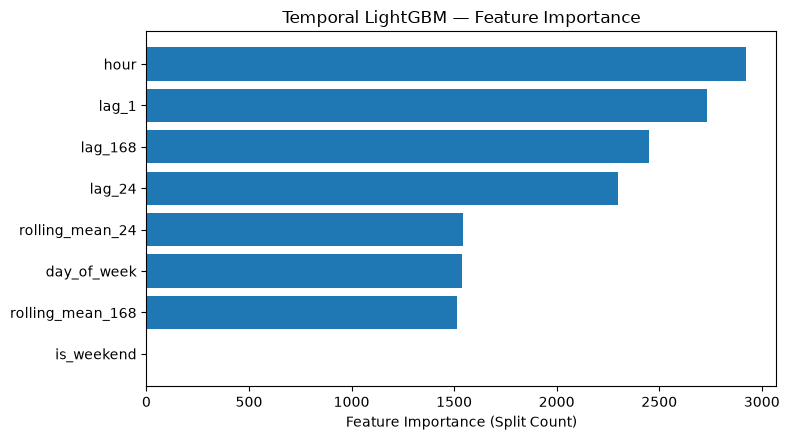

In [31]:
# Step B4.3 — Temporal LightGBM feature importance

importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": temporal_model.feature_importances_,
}).sort_values("importance", ascending=False)

display(importance_df)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4.5))

plt.barh(
    importance_df["feature"][::-1],
    importance_df["importance"][::-1],
)

plt.xlabel("Feature Importance (Split Count)")
plt.title("Temporal LightGBM — Feature Importance")
plt.tight_layout()
plt.show()


In [32]:
# Step B4.4 — Prepare zone-aware temporal features

zone_feature_cols = feature_cols + ["zone_id"]

# Use category dtype for LightGBM
for df in [train_df, val_df, test_df]:
    df["zone_id"] = df["zone_id"].astype("category")

# Ensure the same category definitions across splits
zone_categories = pd.CategoricalDtype(
    categories=sorted(model_df["zone_id"].unique()),
    ordered=False,
)

for df in [train_df, val_df, test_df]:
    df["zone_id"] = df["zone_id"].astype(zone_categories)

print("Feature count:", len(zone_feature_cols))
print("Features:", zone_feature_cols)

print("\nZone dtype:")
print(train_df["zone_id"].dtype)

print("\nUnique zones:")
print("Train:", train_df["zone_id"].nunique())
print("Validation:", val_df["zone_id"].nunique())
print("Test:", test_df["zone_id"].nunique())


Feature count: 9
Features: ['lag_1', 'lag_24', 'lag_168', 'rolling_mean_24', 'rolling_mean_168', 'hour', 'day_of_week', 'is_weekend', 'zone_id']

Zone dtype:
category

Unique zones:
Train: 263
Validation: 263
Test: 263


In [33]:
# Step B4.5 — Train zone-aware temporal LightGBM

X_train_zone = train_df[zone_feature_cols]
X_val_zone = val_df[zone_feature_cols]

zone_temporal_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    random_state=671,
    n_jobs=-1,
    verbosity=-1,
)

zone_temporal_model.fit(
    X_train_zone,
    y_train,
    eval_set=[(X_val_zone, y_val)],
    eval_metric="l1",
    categorical_feature=["zone_id"],
    callbacks=[
        lgb.early_stopping(30, verbose=False),
        lgb.log_evaluation(100),
    ],
)

zone_val_pred = np.clip(
    zone_temporal_model.predict(
        X_val_zone,
        num_iteration=zone_temporal_model.best_iteration_,
    ),
    0,
    None,
)

zone_val_mae = mean_absolute_error(y_val, zone_val_pred)
zone_val_rmse = np.sqrt(
    mean_squared_error(y_val, zone_val_pred)
)

print("Best iteration:", zone_temporal_model.best_iteration_)
print(f"Zone-aware Validation MAE: {zone_val_mae:.4f}")
print(f"Zone-aware Validation RMSE: {zone_val_rmse:.4f}")

print("\nPrevious Temporal-only LightGBM:")
print(f"Validation MAE: {val_mae:.4f}")
print(f"Validation RMSE: {val_rmse:.4f}")


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[100]	valid_0's l1: 3.88402	valid_0's l2: 114.954
[200]	valid_0's l1: 3.70453	valid_0's l2: 105.189
[300]	valid_0's l1: 3.64198	valid_0's l2: 101.317
[400]	valid_0's l1: 3.5994	valid_0's l2: 98.8644
[500]	valid_0's l1: 3.56677	valid_0's l2: 97.0073
Best iteration: 500
Zone-aware Validation MAE: 3.5666
Zone-aware Validation RMSE: 9.8492

Previous Temporal-only LightGBM:
Validation MAE: 3.6731
Validation RMSE: 10.3613


In [34]:
# Step B4.6 — Tune boosting iterations using validation MAE

zone_temporal_model_tuned = lgb.LGBMRegressor(
    objective="regression",
    metric="l1",
    n_estimators=1500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    random_state=671,
    n_jobs=-1,
    verbosity=-1,
)

zone_temporal_model_tuned.fit(
    X_train_zone,
    y_train,
    eval_set=[(X_val_zone, y_val)],
    eval_metric="l1",
    categorical_feature=["zone_id"],
    callbacks=[
        lgb.early_stopping(50, verbose=False),
        lgb.log_evaluation(200),
    ],
)

tuned_pred = np.clip(
    zone_temporal_model_tuned.predict(
        X_val_zone,
        num_iteration=zone_temporal_model_tuned.best_iteration_,
    ),
    0,
    None,
)

tuned_mae = mean_absolute_error(y_val, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_val, tuned_pred))

print("Best iteration:", zone_temporal_model_tuned.best_iteration_)
print(f"Validation MAE: {tuned_mae:.4f}")
print(f"Validation RMSE: {tuned_rmse:.4f}")


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[200]	valid_0's l1: 3.70453
[400]	valid_0's l1: 3.5994
[600]	valid_0's l1: 3.54069
[800]	valid_0's l1: 3.50466
[1000]	valid_0's l1: 3.48313
[1200]	valid_0's l1: 3.46295
[1400]	valid_0's l1: 3.44777
Best iteration: 1500
Validation MAE: 3.4400
Validation RMSE: 9.5671


In [35]:
# Step B4.7 — Save M1 validation predictions

from pathlib import Path

output_dir = Path("../outputs/forecasting")
output_dir.mkdir(parents=True, exist_ok=True)

m1_val_predictions = val_df[
    ["zone_id", "pickup_hour", "pickup_count",
     "hour", "day_of_week", "is_weekend"]
].copy()

m1_val_predictions["m1_prediction"] = tuned_pred

m1_val_predictions["m1_absolute_error"] = np.abs(
    m1_val_predictions["pickup_count"]
    - m1_val_predictions["m1_prediction"]
)

# Check prediction alignment and uniqueness
assert len(m1_val_predictions) == len(val_df)
assert not m1_val_predictions.duplicated(
    ["zone_id", "pickup_hour"]
).any()

assert m1_val_predictions["m1_prediction"].ge(0).all()

# Save validation predictions
output_path = output_dir / "m1_validation_predictions.parquet"

m1_val_predictions.to_parquet(
    output_path,
    index=False,
)

print("Saved:", output_path)
print("Rows:", f"{len(m1_val_predictions):,}")

display(m1_val_predictions.head())


Saved: ../outputs/forecasting/m1_validation_predictions.parquet
Rows: 385,032


,zone_id,pickup_hour,pickup_count,hour,day_of_week,is_weekend,m1_prediction,m1_absolute_error
1533816,1,2025-09-01 00:00:00,0,0,0,0,0.057269,0.057269
1533817,1,2025-09-01 01:00:00,0,1,0,0,0.019495,0.019495
1533818,1,2025-09-01 02:00:00,0,2,0,0,0.019495,0.019495
1533819,1,2025-09-01 03:00:00,0,3,0,0,0.019495,0.019495
1533820,1,2025-09-01 04:00:00,2,4,0,0,0.353646,1.646354


In [36]:
# Step B4.8 — Save M1 model and experiment configuration

import json
import joblib
import lightgbm as lgb

model_path = output_dir / "m1_temporal_zone_lightgbm.joblib"
config_path = output_dir / "m1_experiment_config.json"

joblib.dump(zone_temporal_model_tuned, model_path)

experiment_config = {
    "model": "Temporal + Zone LightGBM",
    "target": target_col,
    "features": zone_feature_cols,
    "train_end_exclusive": "2025-09-01",
    "validation_start": "2025-09-01",
    "validation_end_exclusive": "2025-11-01",
    "test_start": "2025-11-01",
    "test_end_exclusive": "2026-01-01",
    "prediction_horizon": "one-hour-ahead",
    "best_iteration": int(
        zone_temporal_model_tuned.best_iteration_
    ),
    "validation_mae": float(tuned_mae),
    "validation_rmse": float(tuned_rmse),
    "random_state": 671,
    "lightgbm_version": lgb.__version__,
}

with open(config_path, "w") as f:
    json.dump(experiment_config, f, indent=2)

print("Model saved:", model_path)
print("Config saved:", config_path)

display(experiment_config)


Model saved: ../outputs/forecasting/m1_temporal_zone_lightgbm.joblib
Config saved: ../outputs/forecasting/m1_experiment_config.json


{'model': 'Temporal + Zone LightGBM',
 'target': 'pickup_count',
 'features': ['lag_1',
  'lag_24',
  'lag_168',
  'rolling_mean_24',
  'rolling_mean_168',
  'hour',
  'day_of_week',
  'is_weekend',
  'zone_id'],
 'train_end_exclusive': '2025-09-01',
 'validation_start': '2025-09-01',
 'validation_end_exclusive': '2025-11-01',
 'test_start': '2025-11-01',
 'test_end_exclusive': '2026-01-01',
 'prediction_horizon': 'one-hour-ahead',
 'best_iteration': 1500,
 'validation_mae': 3.440048940126518,
 'validation_rmse': 9.567118720118264,
 'random_state': 671,
 'lightgbm_version': '4.7.0'}


## B5 — Network Feature Integration

### Objective

Evaluate whether historical OD network features improve
hourly Yellow Taxi pickup demand forecasting beyond
temporal features and zone identity.

### Model Comparison

- M1: Temporal + Zone LightGBM
- M2: Temporal + Zone + Network LightGBM

### Network Feature Requirements

Each network feature record should include:

- `zone_id`: NYC TLC Taxi Zone identifier
- `feature_as_of`: Latest timestamp covered by source OD data
- Network metrics such as weighted degree, PageRank,
  or community membership

### Leakage Prevention

Network features must be computed exclusively from OD
trips available before the forecasted hour.

If features are updated monthly, the network from prior
months must be used to predict subsequent months.

### Evaluation Protocol

- Train: January–August 2025
- Validation: September–October 2025
- Test: November–December 2025
- Primary metric: MAE
- Secondary metric: RMSE
- Evaluation unit: Zone-hour

M1 and M2 must use identical evaluation observations
and a consistent training and model-selection protocol.
